# 简单RAG中的上下文片段标题（CCH）

检索增强生成（RAG）通过在生成回复之前检索相关的外部知识来提高语言模型的事实准确性。然而，标准的分块方法经常丢失重要上下文，从而使检索效果降低。

上下文片段标题（CCH）通过在嵌入每个片段之前为其添加高级上下文（如文档标题或章节标题）来增强RAG。这提高了检索质量并防止了脱离上下文的回复。

## 本笔记本中的步骤：

1. **数据处理**：加载和预处理文本数据。
2. **带上下文标题的分块**：提取章节标题并将其前置到片段中。
3. **嵌入创建**：将带有上下文增强的片段转换为数值表示。
4. **语义搜索**：根据用户查询检索相关片段。
5. **回复生成**：使用语言模型从检索到的文本生成回复。
6. **评估**：使用评分系统评估回复准确性。

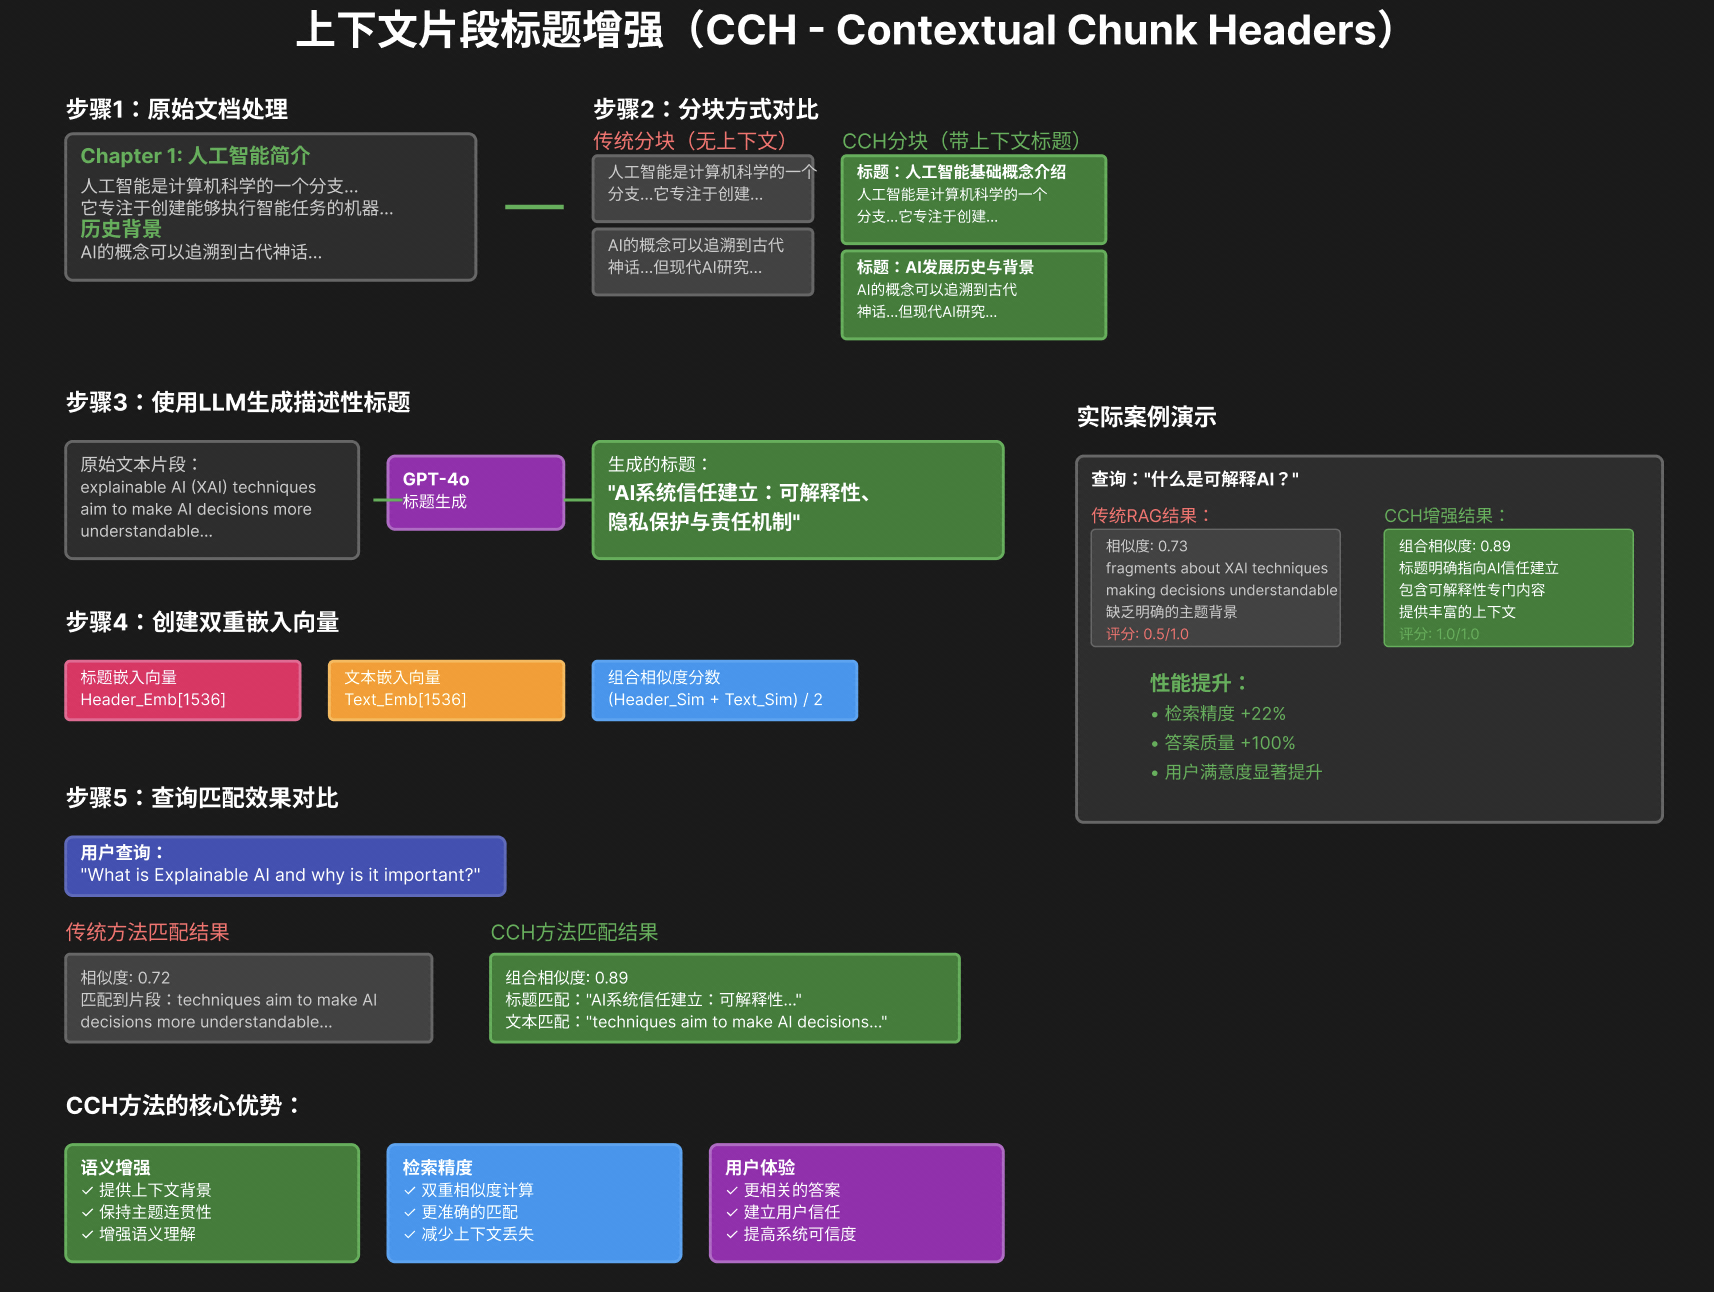

## 环境设置  
首先，我们导入必要的库。

In [1]:
import os
import numpy as np
import json
from openai import OpenAI
import fitz
from tqdm import tqdm# cache: lpf2-00Wac lpf2-0eZ07


## 提取文本并识别章节标题  
我们在从PDF中提取文本的同时，还识别章节标题（作为块的潜在标题）。

In [2]:
# cache: lpf2-01Ub7 lpf2-0fCf0
def extract_text_from_pdf(pdf_path):
    """
    从PDF文件中提取文本并打印前`num_chars`个字符。

    参数:
    pdf_path (str): PDF文件的路径。

    返回:
    str: 从PDF中提取的文本。
    """
    # 打开PDF文件
    mypdf = fitz.open(pdf_path)
    all_text = ""  # 初始化一个空字符串用于存储提取的文本

    # 遍历PDF中的每一页
    for page_num in range(mypdf.page_count):
        page = mypdf[page_num]  # 获取页面
        text = page.get_text("text")  # 从页面提取文本
        all_text += text  # 将提取的文本追加到all_text字符串中

    return all_text  # 返回提取的文本

## 初始化OpenAI API客户端  
我们初始化OpenAI客户端以生成嵌入向量（embeddings）和回复。

In [3]:
from dotenv import load_dotenv
import os

# checksum: lpf2-02Ga6 lpf2-1078c
load_dotenv()  # 加载.env文件（在 .env 里填写 DASHSCOPE_API_KEY）

# 模型调用改为阿里云百炼（OpenAI 兼容接口）：对话模型用 qwen-flash，向量模型用 text-embedding-v4
client = OpenAI(
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
    api_key=os.getenv("DASHSCOPE_API_KEY")  # 从环境变量中获取 API 密钥，不要写进代码或打印
)

# 百炼的 text-embedding-v4 单次最多 10 条文本：这里把 client.embeddings.create 包一层自动分批，
# 返回结构与 OpenAI 相同，后面的代码不用改
_embeddings_create = client.embeddings.create
def _batched_embeddings_create(model, input, **kwargs):
    if isinstance(input, str) or len(input) <= 10:
        return _embeddings_create(model=model, input=input, **kwargs)
    merged = None
    for i in range(0, len(input), 10):
        resp = _embeddings_create(model=model, input=input[i:i + 10], **kwargs)
        if merged is None:
            merged = resp
        else:
            merged.data.extend(resp.data)
    for idx, item in enumerate(merged.data):
        item.index = idx
    return merged
client.embeddings.create = _batched_embeddings_create


## 带有上下文标题的文本分块  
为了改进检索，我们使用大语言模型（LLM）为每个分块生成描述性标题。

In [4]:
# cache: lpf2-03Sec lpf2-11Sfa
def generate_chunk_header(chunk, model="qwen-flash"):
    """
    使用LLM为给定的文本块生成标题/头部。

    参数:
    chunk (str): 作为标题总结的文本块。
    model (str): 用于生成标题的模型。默认值为"qwen-flash"。

    返回:
    str: 生成的标题/头部。
    """
    # 定义系统提示以指导AI的行为
    system_prompt = "Generate a concise and informative title for the given text."
    
    # 基于系统提示和文本块从AI模型生成回复
    response = client.chat.completions.create(
        model=model,
        temperature=0,
        messages=[
            {"role": "system", "content": system_prompt},
            {"role": "user", "content": chunk}
        ]
    )

    # 返回生成的标题/头部，并去除任何前导/尾随空白字符
    return response.choices[0].message.content.strip()

In [5]:
# generated: lpf2-04Q45 lpf2-12F2c
def chunk_text_with_headers(text, n, overlap):
    """
    将文本分割为较小的片段并生成标题。

    参数:
    text (str): 要被分割的完整文本。
    n (int): 每个片段的字符长度。
    overlap (int): 片段之间的重叠字符数量。

    返回:
    List[dict]: 包含 'header' 和 'text' 键的字典列表。
    """
    chunks = []  # 初始化一个空列表以存储片段

    # 使用指定的片段大小和重叠值遍历文本
    for i in range(0, len(text), n - overlap):
        chunk = text[i:i + n]  # 提取一个文本片段
        header = generate_chunk_header(chunk)  # 使用LLM生成片段的标题
        chunks.append({"header": header, "text": chunk})  # 将标题和片段追加到列表中

    return chunks  # 返回包含标题和片段的列表

## 从PDF文件中提取和分块文本  
现在，我们加载PDF文件，提取文本并将其拆分为块。

In [6]:
# 定义PDF文件路径  
# generated: lpf2-05G23 lpf2-13T53
pdf_path = "data/AI_Information.pdf"  

# 从PDF文件中提取文本  
extracted_text = extract_text_from_pdf(pdf_path)  

# 使用标题对提取的文本进行分块  
# 我们使用1000个字符的块大小和200个字符的重叠  
text_chunks = chunk_text_with_headers(extracted_text, 1000, 200)  

# 打印带有生成标题的样本块  
print("Sample Chunk:")
print("Header:", text_chunks[0]['header'])
print("Content:", text_chunks[0]['text'])

Sample Chunk:
Header: **Chapter 1: Introduction to Artificial Intelligence – Foundations and Evolution**
Content: Understanding Artificial Intelligence 
Chapter 1: Introduction to Artificial Intelligence 
Artificial intelligence (AI) refers to the ability of a digital computer or computer-controlled robot 
to perform tasks commonly associated with intelligent beings. The term is frequently applied to 
the project of developing systems endowed with the intellectual processes characteristic of 
humans, such as the ability to reason, discover meaning, generalize, or learn from past 
experience. Over the past few decades, advancements in computing power and data availability 
have significantly accelerated the development and deployment of AI. 
Historical Context 
The idea of artificial intelligence has existed for centuries, often depicted in myths and fiction. 
However, the formal field of AI research began in the mid-20th century. The Dartmouth Workshop 
in 1956 is widely considered the

## 为标题和文本创建嵌入
我们为标题和文本创建嵌入，以提高检索准确性。

In [7]:
# cache: lpf2-06Y19 lpf2-14Ad9
def create_embeddings(text, model="text-embedding-v4"):
    """
    为给定的文本创建嵌入。

    参数:
    text (str): 要嵌入的输入文本。
    model (str): 要使用的嵌入模型。默认值为 "text-embedding-v4"。

    返回:
    dict: 包含输入文本嵌入结果的回复。
    """
    # 使用指定的模型和输入文本创建嵌入
    response = client.embeddings.create(
        model=model,
        input=text
    )
    # 从回复中返回嵌入结果
    return response.data[0].embedding

In [8]:
# 为每个片段生成嵌入
# revision: lpf2-07Ne9 lpf2-15H4a
embeddings = []  # 初始化一个空列表以存储嵌入

# 使用进度条迭代每个文本片段
for chunk in tqdm(text_chunks, desc="Generating embeddings"):
    # 为片段的文本创建嵌入
    text_embedding = create_embeddings(chunk["text"])
    # 为片段的标题创建嵌入
    header_embedding = create_embeddings(chunk["header"])
    # 将片段的标题、文本及其嵌入追加到列表中
    embeddings.append({"header": chunk["header"], "text": chunk["text"], "embedding": text_embedding, "header_embedding": header_embedding})

Generating embeddings:   0%|          | 0/42 [00:00<?, ?it/s]

Generating embeddings:   2%|▏         | 1/42 [00:00<00:11,  3.49it/s]

Generating embeddings:   5%|▍         | 2/42 [00:00<00:12,  3.22it/s]

Generating embeddings:   7%|▋         | 3/42 [00:00<00:12,  3.14it/s]

Generating embeddings:  10%|▉         | 4/42 [00:01<00:11,  3.35it/s]

Generating embeddings:  12%|█▏        | 5/42 [00:01<00:11,  3.12it/s]

... (34 outputs left out)

Generating embeddings:  95%|█████████▌| 40/42 [00:13<00:00,  2.77it/s]

Generating embeddings:  98%|█████████▊| 41/42 [00:13<00:00,  2.65it/s]

Generating embeddings: 100%|██████████| 42/42 [00:13<00:00,  2.84it/s]

Generating embeddings: 100%|██████████| 42/42 [00:13<00:00,  3.02it/s]

## 执行语义搜索  
我们通过余弦相似度来为用户查询找到最相关文本片段。

In [9]:
# checksum: lpf2-08Jcd lpf2-16Sff
def cosine_similarity(vec1, vec2):
    """
    计算两个向量之间的余弦相似度。

    参数:
    vec1 (np.ndarray): 第一个向量。
    vec2 (np.ndarray): 第二个向量。

    返回:
    float: 余弦相似度得分。
    """
    return np.dot(vec1, vec2) / (np.linalg.norm(vec1) * np.linalg.norm(vec2))

In [10]:
# revision: lpf2-09A72 lpf2-1761f
def semantic_search(query, chunks, k=5):
    """
    根据查询搜索最相关的文本块。

    参数:
    query (str): 用户查询。
    chunks (List[dict]): 包含嵌入的文本块列表。
    k (int): 返回的结果数量。

    返回:
    List[dict]: 最相关的前k个文本块。
    """
    # 为查询创建嵌入
    query_embedding = create_embeddings(query)

    similarities = []  # 初始化一个列表用于存储相似度分数
    
    # 遍历每个文本块以计算相似度分数
    for chunk in chunks:
        # 计算查询嵌入与文本块文本嵌入之间的余弦相似度
        sim_text = cosine_similarity(np.array(query_embedding), np.array(chunk["embedding"]))
        # 计算查询嵌入与文本块标题嵌入之间的余弦相似度
        sim_header = cosine_similarity(np.array(query_embedding), np.array(chunk["header_embedding"]))
        # 计算平均相似度分数
        avg_similarity = (sim_text + sim_header) / 2
        # 将文本块及其平均相似度分数追加到列表中
        similarities.append((chunk, avg_similarity))

    # 按相似度分数降序排序文本块
    similarities.sort(key=lambda x: x[1], reverse=True)
    # 返回最相关的前k个文本块
    return [x[0] for x in similarities[:k]]

## 对提取的块运行查询

In [11]:
# 加载验证数据  
# cache: lpf2-0aZdb lpf2-184b6
with open('data/val.json') as f:  
    data = json.load(f)  

query = data[0]['question']  

# 检索与查询最相关的前 2 个文本片段  
top_chunks = semantic_search(query, embeddings, k=2)  

# 打印结果  
print("Query:", query)  
for i, chunk in enumerate(top_chunks):  
    print(f"Header {i+1}: {chunk['header']}")  
    print(f"Content:\n{chunk['text']}\n")

Query: What is 'Explainable AI' and why is it considered important?
Header 1: Building Trust in AI: Transparency, Explainability, Privacy, and Accountability
Content:
systems. Explainable AI (XAI) 
techniques aim to make AI decisions more understandable, enabling users to assess their 
fairness and accuracy. 
Privacy and Data Protection 
AI systems often rely on large amounts of data, raising concerns about privacy and data 
protection. Ensuring responsible data handling, implementing privacy-preserving techniques, 
and complying with data protection regulations are crucial. 
Accountability and Responsibility 
Establishing accountability and responsibility for AI systems is essential for addressing potential 
harms and ensuring ethical behavior. This includes defining roles and responsibilities for 
developers, deployers, and users of AI systems. 
Chapter 20: Building Trust in AI 
Transparency and Explainability 
Transparency and explainability are key to building trust in AI. Making A

## 基于检索块生成回复

In [12]:
# 定义AI助手的系统提示
# cache: lpf2-0bI32 lpf2-19Y64
system_prompt = "You are an AI assistant that strictly answers based on the given context. If the answer cannot be derived directly from the provided context, respond with: 'I do not have enough information to answer that.'"

def generate_response(system_prompt, user_message, model="qwen-flash"):
    """
    基于系统提示和用户消息生成AI模型的回复。

    参数:
    system_prompt (str): 指导AI行为的系统提示。
    user_message (str): 用户的消息或查询。
    model (str): 用于生成回复的模型。默认为"meta-llama/Llama-2-7B-chat-hf"。

    返回:
    dict: AI模型的回复。
    """
    response = client.chat.completions.create(
        model=model,
        temperature=0,
        messages=[
            {"role": "system", "content": system_prompt},
            {"role": "user", "content": user_message}
        ]
    )
    return response

# 根据顶级片段创建用户提示
user_prompt = "\n".join([f"Header: {chunk['header']}\nContent:\n{chunk['text']}" for chunk in top_chunks])
user_prompt = f"{user_prompt}\nQuestion: {query}"

# 生成AI回复
ai_response = generate_response(system_prompt, user_prompt)
print(ai_response.choices[0].message.content)

Explainable AI (XAI) refers to techniques and methods that make the decision-making processes of AI systems more transparent and understandable to humans. It aims to provide insights into how AI models arrive at their conclusions, enabling users to assess the fairness, accuracy, and reliability of AI decisions.

XAI is considered important because it enhances trust in AI systems by making their behavior interpretable. When users can understand why an AI made a particular decision, they are more likely to accept and rely on its outputs. This is especially critical in high-stakes domains like healthcare, finance, and criminal justice, where accountability and ethical considerations are paramount. Additionally, XAI supports better debugging, improves system reliability, and helps ensure compliance with regulations by promoting transparency and responsibility in AI deployment.


## 评估AI回复
我们将AI的回复与预期答案进行比较，并分配一个分数。

In [13]:
# 定义评估系统提示
# cache: lpf2-0cW08
evaluate_system_prompt = """You are an intelligent evaluation system. 
Assess the AI assistant's response based on the provided context. 
- Assign a score of 1 if the response is very close to the true answer. 
- Assign a score of 0.5 if the response is partially correct. 
- Assign a score of 0 if the response is incorrect.
Return only the score (0, 0.5, or 1)."""

# 从验证数据中提取真实答案
true_answer = data[0]['ideal_answer']

# 构造评估提示
evaluation_prompt = f"""
User Query: {query}
AI Response: {ai_response}
True Answer: {true_answer}
{evaluate_system_prompt}
"""

# 生成评估分数
evaluation_response = generate_response(evaluate_system_prompt, evaluation_prompt)

# 打印评估分数
print("Evaluation Score:", evaluation_response.choices[0].message.content)

Evaluation Score: 1


In [ ]:
# checksum: lpf2-0dZ82
